# European options: Monte Carlo convergence and confidence-interval coverage

European calls and puts have a closed-form Black-Scholes price, so the Monte Carlo error can be measured exactly. This notebook does three things:

1. Sweeps the path count $N$ from $10^3$ to about $3 \times 10^6$ and plots the root-mean-square error (RMSE) against Black-Scholes, with an $N^{-1/2}$ reference line.
2. Checks for bias: at each $N$, the mean error over 30 independent runs should be within a few standard errors of zero.
3. Checks the reported 95% confidence intervals: over 2,000 independent runs, about 95% of them should contain the Black-Scholes price.

All simulations use one time step. A European payoff only needs $S_T$, and the log-space GBM step is exact, so this is the same estimator as a fine grid.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mc_pricer.bs_analytics import bs_price
from mc_pricer.gbm import simulate_gbm_paths
from mc_pricer.mc import mc_price_european
from mc_pricer.mc_results import discount_payoffs
from mc_pricer.payoffs import european_payoff
from mc_pricer.rng import RNG

FIG_DIR = Path.cwd().parent / "docs" if Path.cwd().name == "notebooks" else Path("docs")
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.precision", 5)

## Parameters

In [2]:
S0, K, r, T, sigma = 100.0, 100.0, 0.02, 1.0, 0.25
option_types = ["call", "put"]
n_grid = np.unique(np.logspace(3, 6.5, num=8).astype(int))
n_replications = 30
master_seed = 20260215

bs_truth = {opt: float(bs_price(S0, K, T, r, sigma, opt)) for opt in option_types}
bs_truth

{'call': 10.870558490557599, 'put': 8.890425821233109}

## Path-count sweep

For each $N$, 30 independent runs. Call and put are priced from the same terminal prices in each run. `bias_z` is the mean error over the 30 runs divided by its standard error; for an unbiased estimator it is roughly standard normal.

In [3]:
seed_rng = np.random.default_rng(master_seed)
records = []
for N in n_grid:
    for seed in seed_rng.integers(1, 2**31 - 1, size=n_replications):
        ST = simulate_gbm_paths(S0, r, sigma, T, 1, int(N), rng=RNG(seed=int(seed)))[:, -1]
        for opt in option_types:
            res = mc_price_european(ST, K, r, T, opt)
            records.append(
                {
                    "N": int(N),
                    "option": opt,
                    "error": res["price"] - bs_truth[opt],
                    "stderr": res["stderr"],
                }
            )
sweep = pd.DataFrame(records)

summary = sweep.groupby(["option", "N"]).agg(
    rmse=("error", lambda e: np.sqrt(np.mean(e**2))),
    mean_error=("error", "mean"),
    mean_stderr=("stderr", "mean"),
)
summary["bias_z"] = summary["mean_error"] / (summary["mean_stderr"] / np.sqrt(n_replications))
summary

rmse  mean_error  mean_stderr   bias_z
option N                                                 
call   1000     0.47604     0.01284      0.55620  0.12641
       3162     0.30593     0.08281      0.31509  1.43952
       10000    0.13000    -0.05042      0.17486 -1.57937
       31622    0.08202     0.00499      0.09898  0.27596
       100000   0.05778     0.00238      0.05557  0.23418
       316227   0.02438    -0.00278      0.03128 -0.48730
       1000000  0.01615    -0.00316      0.01759 -0.98342
       3162277  0.01060    -0.00164      0.00989 -0.90815
put    1000     0.33519     0.00072      0.37621  0.01055
       3162     0.18134    -0.01994      0.21199 -0.51528
       10000    0.13244    -0.00427      0.11930 -0.19615
       31622    0.07924     0.01312      0.06713  1.07050
       100000   0.03753    -0.00761      0.03771 -1.10483
       316227   0.02266    -0.00390      0.02121 -1.00609
       1000000  0.01102     0.00051      0.01193  0.23266
       3162277  0.00644     0.00233      0.00671  1.90281

## RMSE against $N$

The dotted line is $\sigma_{\text{payoff}} / \sqrt{N}$, where $\sigma_{\text{payoff}}$ is the standard deviation of the discounted payoff from a separate 2-million-path pilot run. For an unbiased estimator this is the theoretical RMSE, so the line is drawn at its predicted level rather than fitted through the first point.

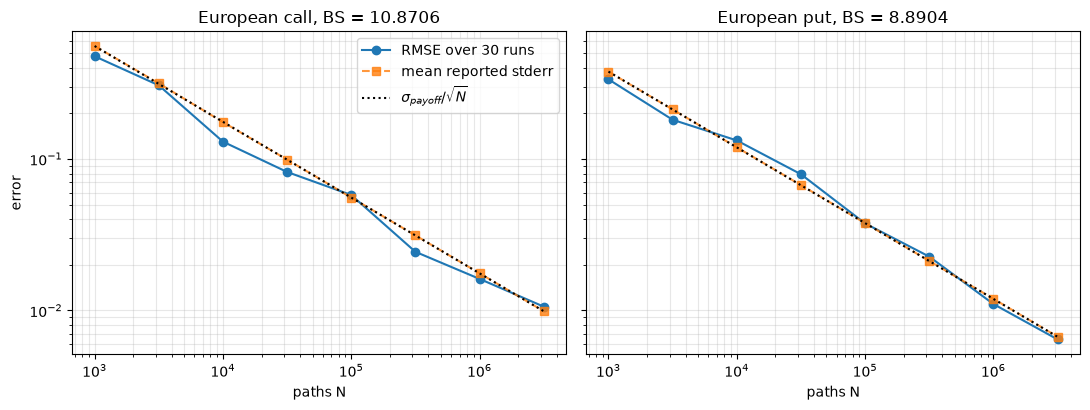

call: fitted log-log slope of RMSE vs N = -0.483
put: fitted log-log slope of RMSE vs N = -0.493


In [4]:
pilot_ST = simulate_gbm_paths(S0, r, sigma, T, 1, 2_000_000, rng=RNG(seed=1))[:, -1]
payoff_sd = {
    opt: discount_payoffs(european_payoff(pilot_ST, K, opt), r, T).std(ddof=1)
    for opt in option_types
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, opt in zip(axes, option_types, strict=True):
    s = summary.loc[opt]
    N = s.index.to_numpy()
    ax.loglog(N, s["rmse"], "o-", label="RMSE over 30 runs")
    ax.loglog(N, s["mean_stderr"], "s--", alpha=0.8, label="mean reported stderr")
    ax.loglog(N, payoff_sd[opt] / np.sqrt(N), "k:", label=r"$\sigma_{payoff}/\sqrt{N}$")
    ax.set_title(f"European {opt}, BS = {bs_truth[opt]:.4f}")
    ax.set_xlabel("paths N")
    ax.grid(True, which="both", alpha=0.3)
axes[0].set_ylabel("error")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "european_convergence.png", dpi=120)
plt.show()

for opt in option_types:
    slope = np.polyfit(np.log(summary.loc[opt].index), np.log(summary.loc[opt]["rmse"]), 1)[0]
    print(f"{opt}: fitted log-log slope of RMSE vs N = {slope:.3f}")

## Confidence-interval coverage

For each $N$ and each strike, 2,000 independent runs. Each run reports a 95% interval, price $\pm 1.96 \times$ stderr. The table gives the fraction of intervals that contain the Black-Scholes price. With 2,000 runs, the binomial standard error of a 95% coverage estimate is about 0.5 percentage points.

A deep out-of-the-money call (K = 160) is included because its payoff is zero on most paths and heavily right-skewed. The normal approximation behind the interval is then poor at small $N$.

In [5]:
n_runs = 2_000
coverage_rows = []
for strike in (100.0, 160.0):
    truth = bs_price(S0, strike, T, r, sigma, "call")
    for N in (100, 1_000, 10_000):
        covered = 0
        for seed in range(n_runs):
            ST = simulate_gbm_paths(S0, r, sigma, T, 1, N, rng=RNG(seed=10_000 + seed))[:, -1]
            res = mc_price_european(ST, strike, r, T, "call")
            covered += res["ci_low"] <= truth <= res["ci_high"]
        coverage_rows.append({"K": strike, "N": N, "BS price": truth, "coverage": covered / n_runs})
coverage = pd.DataFrame(coverage_rows)
coverage["coverage_se"] = np.sqrt(coverage["coverage"] * (1 - coverage["coverage"]) / n_runs)
coverage

,K,N,BS price,coverage,coverage_se
0,100.0,100,10.87056,0.9455,0.00508
1,100.0,1000,10.87056,0.9535,0.00471
2,100.0,10000,10.87056,0.9455,0.00508
3,160.0,100,0.44427,0.7570,0.00959
4,160.0,1000,0.44427,0.9255,0.00587
5,160.0,10000,0.44427,0.9470,0.00501


## Interpretation

**Rate.** The fitted RMSE slopes are about $-0.48$ (call) and $-0.49$ (put), and the RMSE curve sits on the $\sigma_{\text{payoff}}/\sqrt{N}$ line. The error falls at the $N^{-1/2}$ rate and at the level the payoff variance predicts.

The reported standard error also has slope $-1/2$, but that is automatic: it is $\hat\sigma/\sqrt{N}$ by construction. On its own it says nothing about bias. A biased estimator would show the same stderr slope while its RMSE flattened out at the size of the bias.

**Bias.** All 16 `bias_z` values are within $\pm 2$, so there is no detectable bias at these sample sizes. That is expected here: the GBM terminal value is simulated exactly, so the only error is sampling error.

**Coverage.** For the at-the-money call the 95% intervals contain the Black-Scholes price 94.6% to 95.4% of the time at every $N$, within sampling error of 95%. For the K = 160 call coverage is 75.7% at $N = 100$, 92.6% at $N = 1{,}000$ and 94.7% at $N = 10{,}000$. With 100 paths only a handful finish in the money. Runs that happen to see few of them report a low price and a small stderr together, so their intervals fall short of the true value. The normal-approximation interval needs enough nonzero payoffs before it can be trusted.